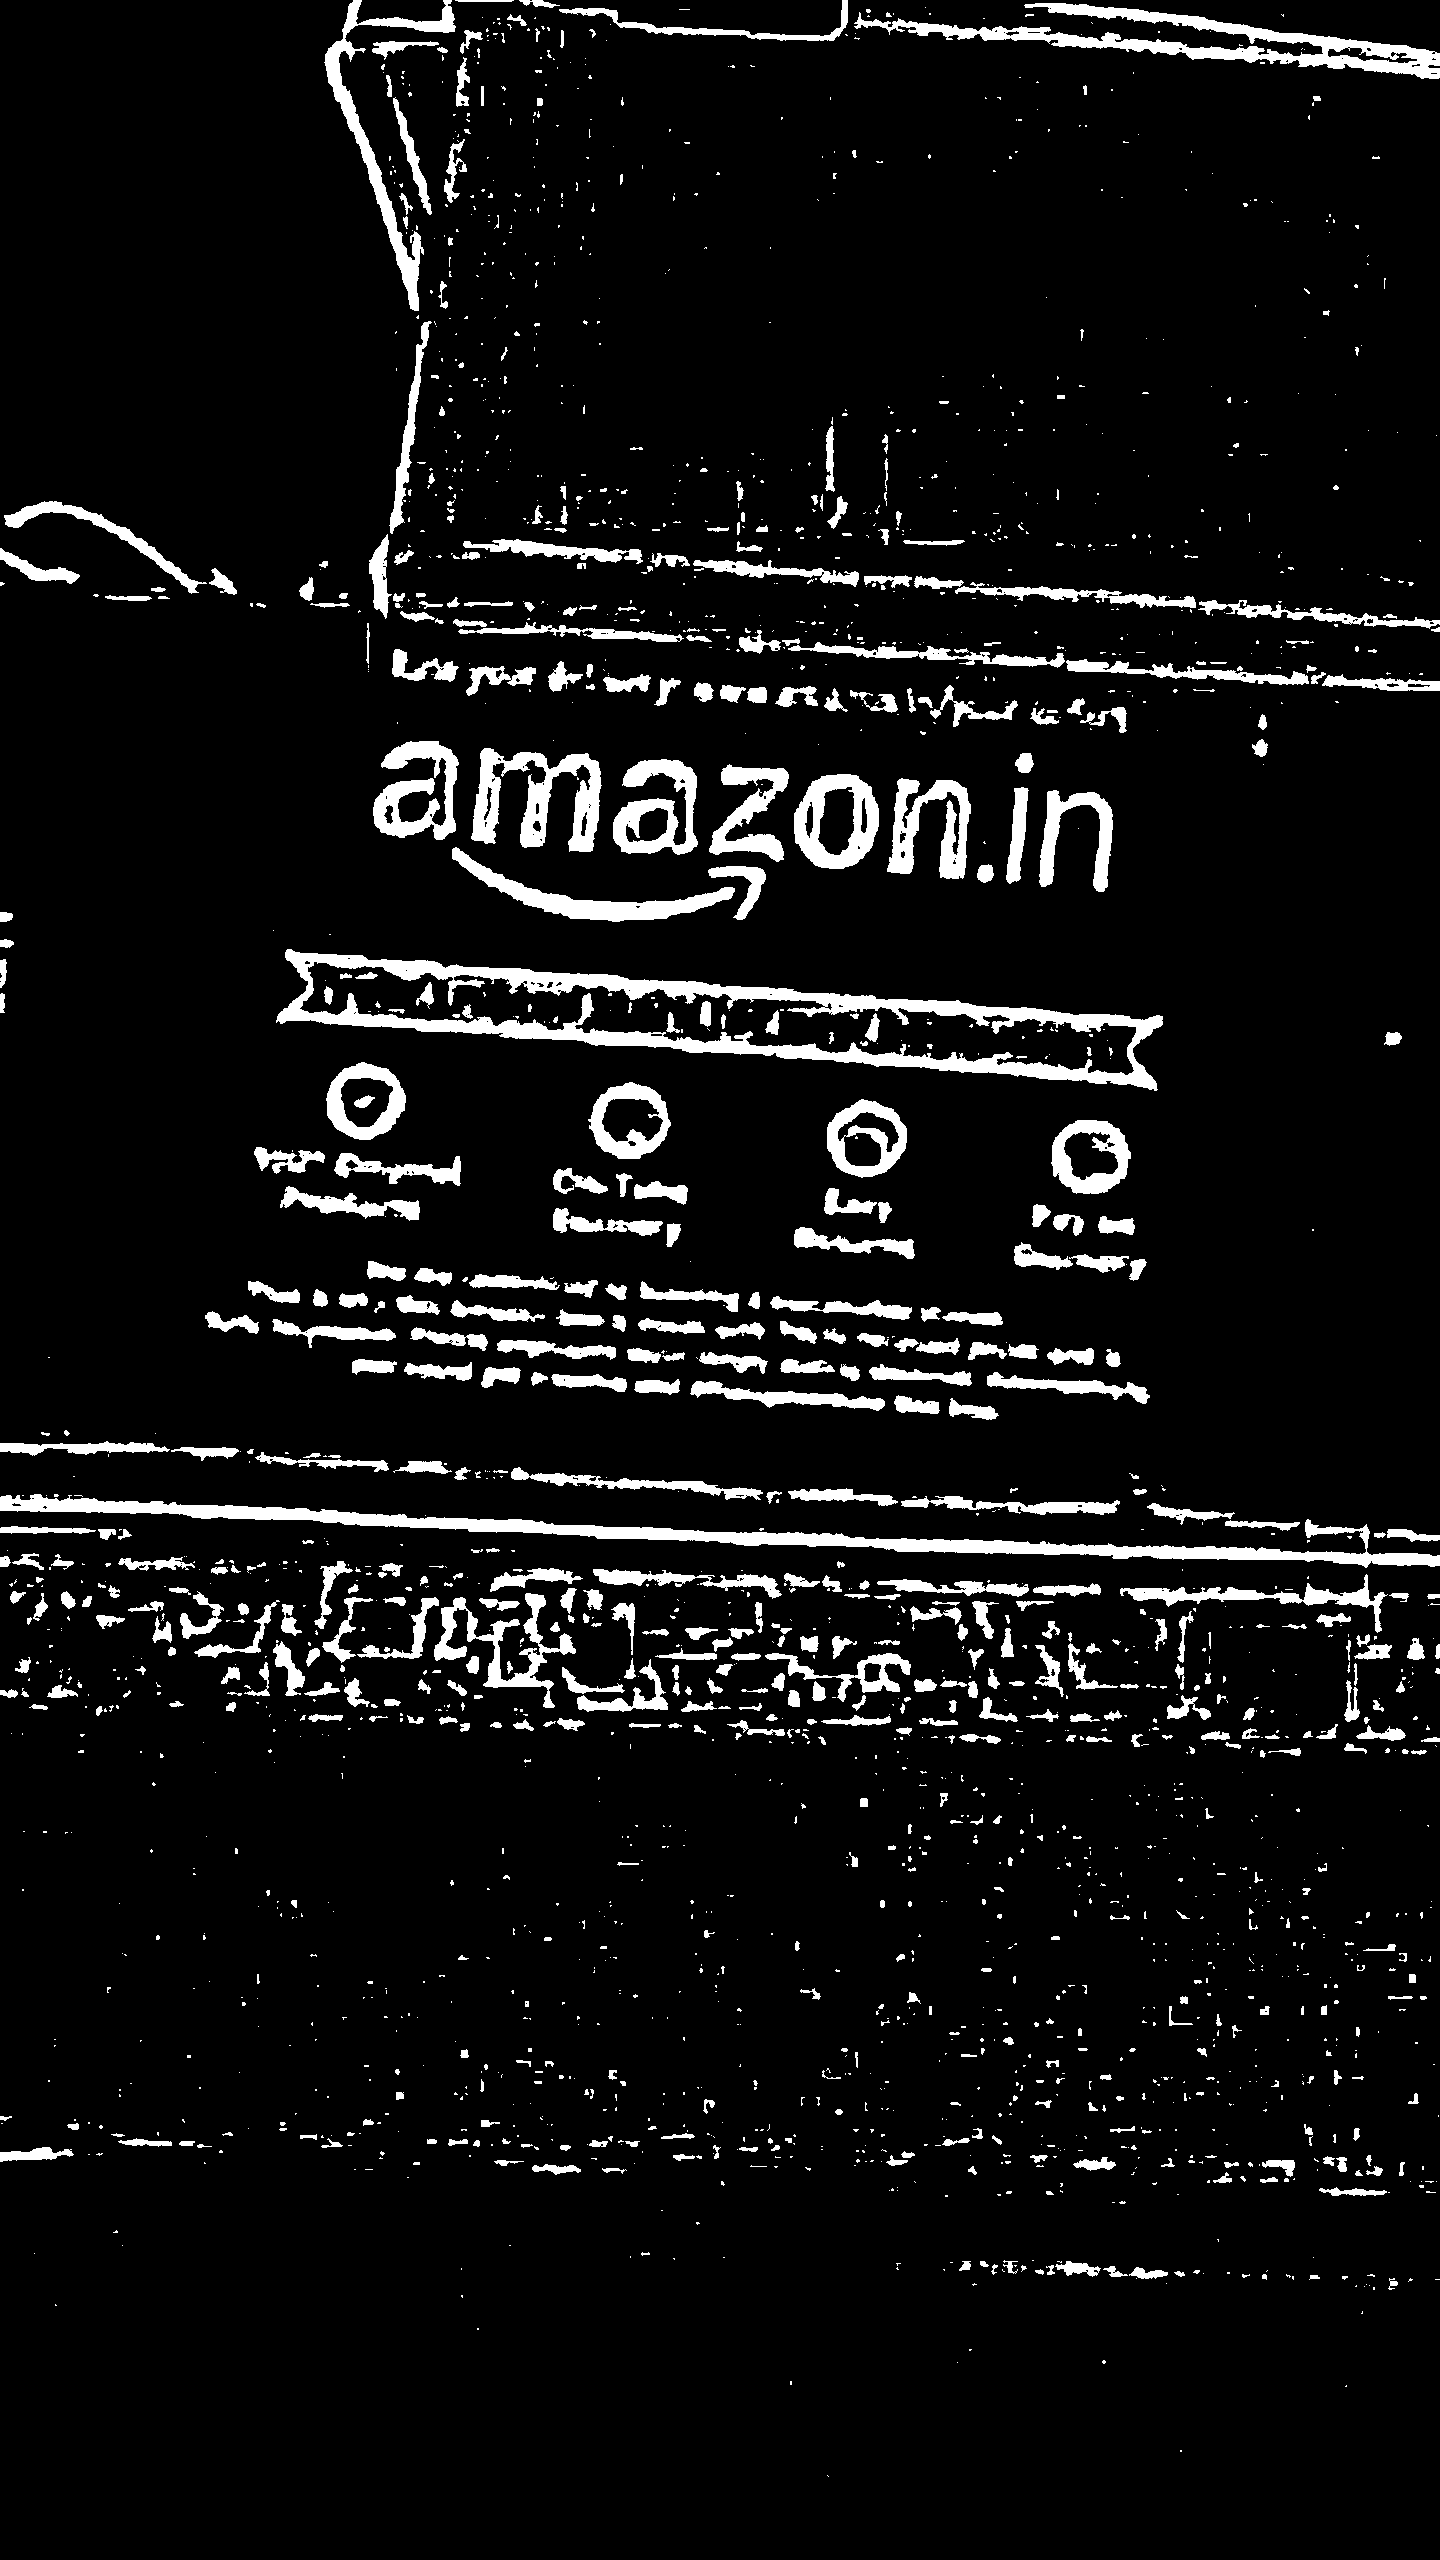

Text Extracted from Threshed Image:- 
 - own fo

poo
awe
a Tk
; eo.
‘ Job
-, - os
s, : opt
elt ?
7 - - *
ban
an -
st we at ‘
os

OR ae ge

oe

Tt Bl ew, ~
. iu. acl -
“a ie

“
7
th ee
: ‘ye am
to “a
‘oof
'
abe
a

Text Extracted from Plain Image:- 
 


In [ ]:
from PIL import Image
import pytesseract
import cv2 as cv
import numpy as np

img = Image.open(r"..\data\processed\capturedImage.png")
# img = Image.open(r"../data\raw\Test_Text.png")
img_cv = np.array(img)
gray_img = cv.cvtColor(img_cv, cv.COLOR_RGB2GRAY)
kernel = cv.getStructuringElement(cv.MORPH_RECT, (51, 51))
background = cv.morphologyEx(gray_img, cv.MORPH_CLOSE, kernel)
flattened_gray = cv.divide(gray_img, background, scale=255)

height, width = flattened_gray.shape
img_large = cv.resize(flattened_gray, (width * 2, height * 2), interpolation=cv.INTER_CUBIC)
blur_img = cv.GaussianBlur(img_large, (3, 3), 0)
threshed_img = cv.adaptiveThreshold(blur_img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, blockSize=31, C=7)
display(Image.fromarray(threshed_img))

custom_config = r'--oem 3 --psm 3'
text = pytesseract.image_to_string(threshed_img, config=custom_config)
print(f"Text Extracted from Threshed Image:- \n {text}")
# print()
# print()
# print()
# print()
print(f"Text Extracted from Plain Image:- \n {pytesseract.image_to_string(img_large)}")